# 01 — Setup check

Checks that the environment works before any pipeline code is written:

1. import the libraries,
2. check that PyTorch can see and use the GPU,
3. load and show one DRIVE image with its field-of-view mask and expert annotation.

## 1. Imports

In [1]:
from pathlib import Path
import sys

import numpy as np
import cv2
import skimage
import torch
import torchvision
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

print(f"Python       {sys.version.split()[0]}")
print(f"numpy        {np.__version__}")
print(f"OpenCV       {cv2.__version__}")
print(f"scikit-image {skimage.__version__}")
print(f"torch        {torch.__version__}")
print(f"torchvision  {torchvision.__version__}")
print(f"matplotlib   {matplotlib.__version__}")

Python       3.13.5
numpy        2.5.4
OpenCV       5.0.0
scikit-image 0.26.0
torch        2.6.0+cu124
torchvision  0.21.0+cu124
matplotlib   3.11.2


## 2. PyTorch and CUDA

`requirements.txt` pins the CUDA 12.4 build because the NVIDIA driver (550) supports CUDA 12.4 at most. If `cuda available` is `False`, the wrong torch build is installed.

In [2]:
print("cuda available :", torch.cuda.is_available())
print("torch CUDA     :", torch.version.cuda)
print("cuDNN          :", torch.backends.cudnn.version())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device         :", device)

if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU            : {props.name}, {props.total_memory / 1024**3:.1f} GB")

cuda available : False
torch CUDA     : 12.4
cuDNN          : 90100
device         : cpu


/home/tayeb/dev/dscv/proj_morph/.venv/lib/python3.13/site-packages/torch/cuda/__init__.py:129: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0


## 3. One DRIVE image

- The `.tif` images are LZW-compressed: `skimage.io.imread` can't read them without `imagecodecs`, so OpenCV is used. OpenCV returns **BGR**, converted to RGB for display.
- Masks and annotations are `.gif`, read with PIL and binarised with `> 0` (`test/2nd_manual` uses {0, 1}, the others {0, 255}).
- The green channel is shown because pipeline A starts from it: vessels have the best contrast there.

In [3]:
# Find the project root (the folder containing data/) so the notebook works
# whether Jupyter was started from the project root or from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "DRIVE").is_dir())
DRIVE = ROOT / "data" / "DRIVE"
print("DRIVE:", DRIVE)

for split in ["training", "test"]:
    for sub in sorted(p.name for p in (DRIVE / split).iterdir()):
        print(f"  {split}/{sub:<11} {len(list((DRIVE / split / sub).iterdir()))} files")

DRIVE: /home/tayeb/dev/dscv/proj_morph/data/DRIVE
  training/1st_manual  20 files
  training/images      20 files
  training/mask        20 files
  test/1st_manual  20 files
  test/2nd_manual  20 files
  test/images      20 files
  test/mask        20 files


In [4]:
def read_rgb(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def read_binary(path):
    return np.array(Image.open(path)) > 0


IMG_ID = 22  # training images are 21-40
image = read_rgb(DRIVE / "training" / "images" / f"{IMG_ID}_training.tif")
fov = read_binary(DRIVE / "training" / "mask" / f"{IMG_ID}_training_mask.gif")
vessels = read_binary(DRIVE / "training" / "1st_manual" / f"{IMG_ID}_manual1.gif")

print("image  :", image.shape, image.dtype, image.min(), image.max())
print("fov    :", fov.shape, fov.dtype, f"{fov.mean():.1%} of pixels")
print("vessels:", vessels.shape, vessels.dtype, f"{vessels[fov].mean():.1%} of the FOV")

image  : (584, 565, 3) uint8 0 255
fov    : (584, 565) bool 69.0% of pixels
vessels: (584, 565) bool 13.1% of the FOV


### Métriques et opérateurs
On importe `dice_in_fov` et `cldice_in_fov` depuis `src/metrics.py` : le même code d'évaluation servira aux trois pipelines.
Le clDice compare les squelettes (amincissement) des vaisseaux, il pénalise donc les vaisseaux coupés.

In [5]:
# Make the project root importable so the shared `src` code can be used from the notebook.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.metrics import dice_in_fov, cldice_in_fov

# Morphological operators and Otsu threshold, called directly from scikit-image below.
from skimage import morphology
from skimage.filters import threshold_otsu

# Sanity check: the annotation compared with itself must score 1.
print("Dice   (truth vs truth):", dice_in_fov(vessels, vessels, fov))
print("clDice (truth vs truth):", cldice_in_fov(vessels, vessels, fov))

Dice   (truth vs truth): 1.0
clDice (truth vs truth): 1.0


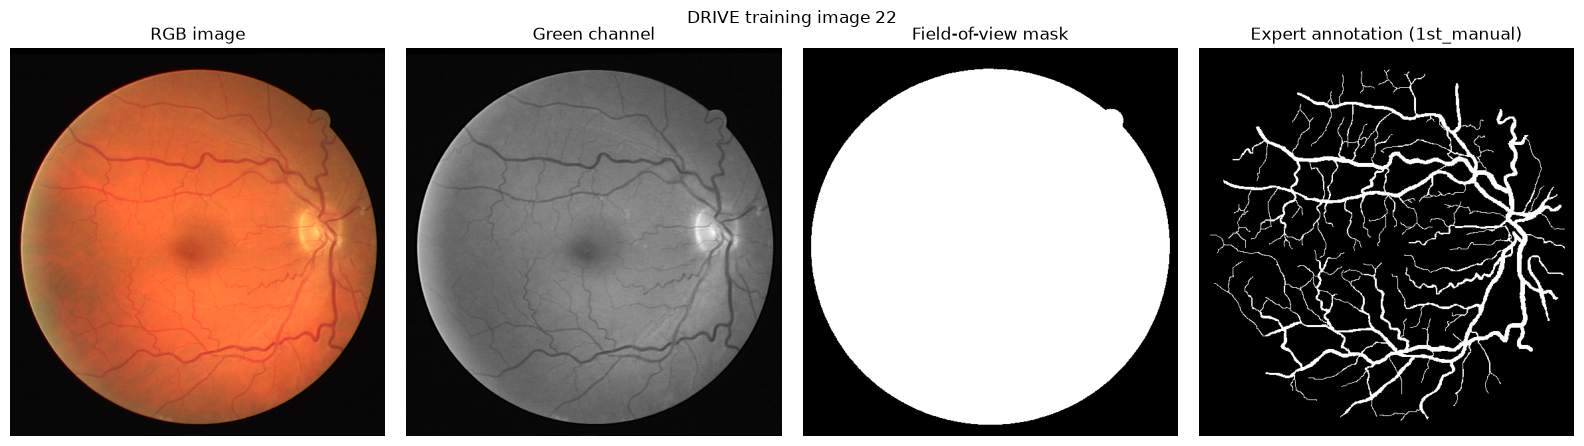

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
panels = [
    (image, None, "RGB image"),
    (image[..., 1], "gray", "Green channel"),
    (fov, "gray", "Field-of-view mask"),
    (vessels, "gray", "Expert annotation (1st_manual)"),
]
for ax, (img, cmap, title) in zip(axes, panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle(f"DRIVE training image {IMG_ID}")
plt.tight_layout()
plt.show()

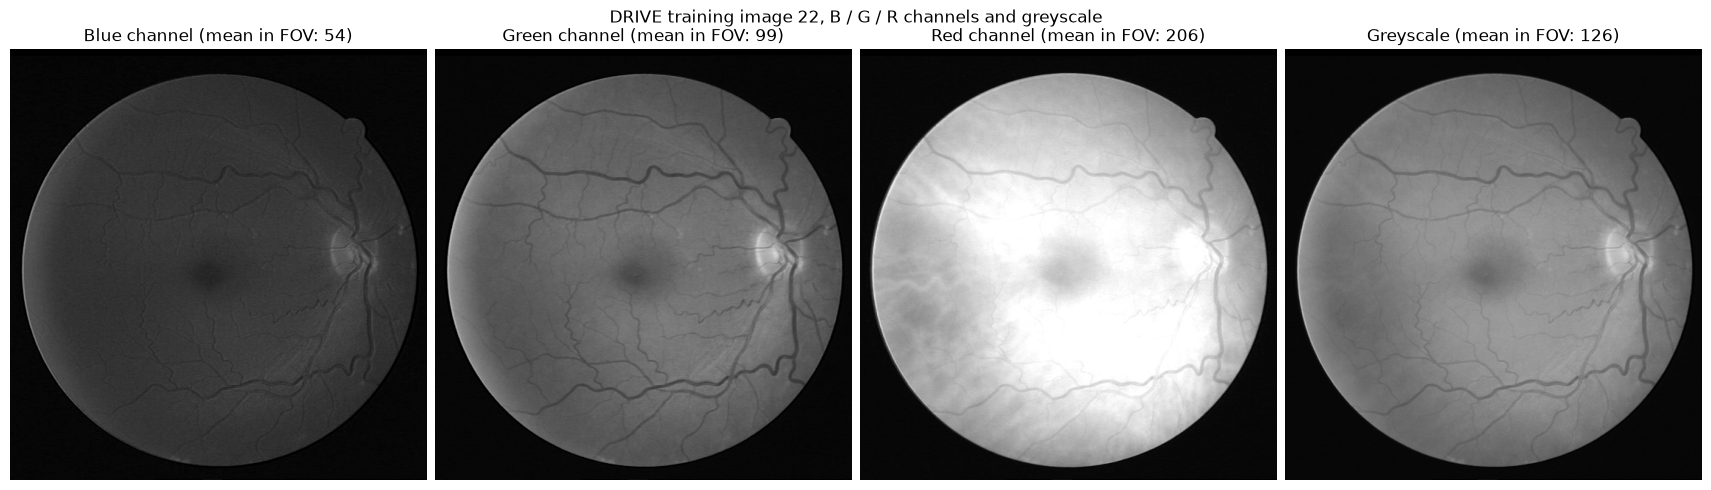

In [7]:
# The three colour channels separately, in OpenCV's B, G, R order, next to the
# usual greyscale conversion (0.299 R + 0.587 G + 0.114 B).
# `image` is RGB, so blue is index 2 and red is index 0. All panels share the
# same 0-255 grey scale so their brightness can be compared directly.
grey = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
panels = [("Blue channel", image[..., 2]), ("Green channel", image[..., 1]),
          ("Red channel", image[..., 0]), ("Greyscale", grey)]

fig, axes = plt.subplots(1, 4, figsize=(17, 4.8), layout="constrained")
for ax, (name, img) in zip(axes, panels):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{name} (mean in FOV: {img[fov].mean():.0f})")
    ax.axis("off")
fig.suptitle(f"DRIVE training image {IMG_ID}, B / G / R channels and greyscale")
plt.show()

## 4. Pipeline A : morphologie seule
**Étape 3 : canal vert dans le champ de vue (FOV).** Hors du FOV, les pixels sont remplacés par la moyenne du vert dans le FOV,
pour que le bord noir ne soit pas vu comme une grande structure sombre par le top-hat. Simple masquage, pas encore d'opérateur morphologique.

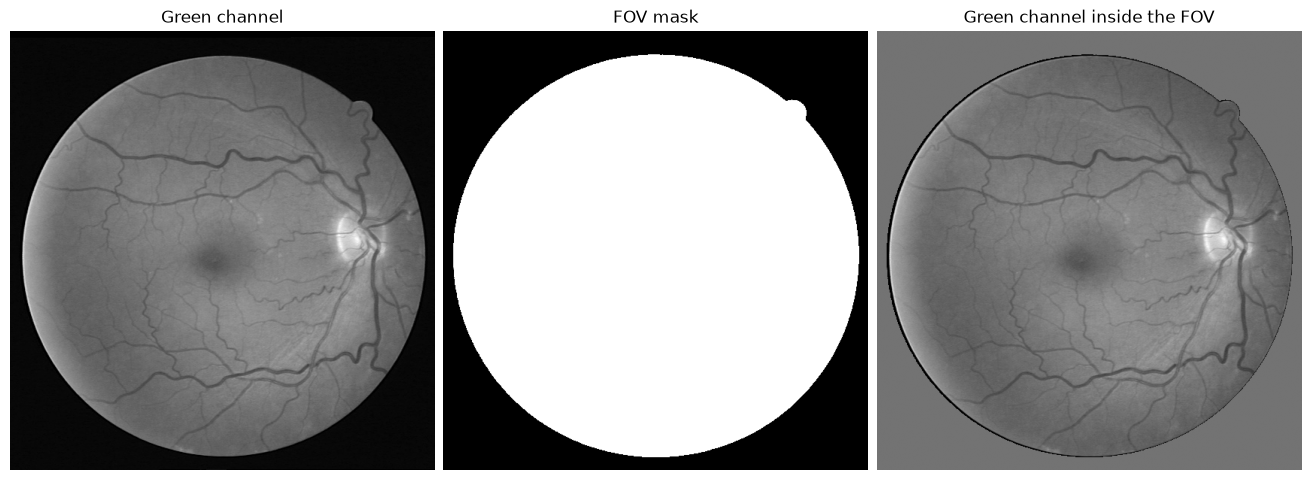

In [8]:
green = image[..., 1]

# Keep the green values inside the FOV; outside, use the mean green value of the FOV.
green_fov = green.copy()
green_fov[~fov] = int(green[fov].mean())

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for ax, (img, title) in zip(axes, [(green, "Green channel"), (fov, "FOV mask"),
                                   (green_fov, "Green channel inside the FOV")]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Étape 4 : top-hat noir (top-hat conjugué)**, `black_tophat` = fermeture − image.
Il fait ressortir les structures sombres plus étroites que l'élément structurant (un disque), donc les vaisseaux.
Trois rayons sont comparés : un petit disque ne garde que les fins vaisseaux, un grand garde aussi les gros.

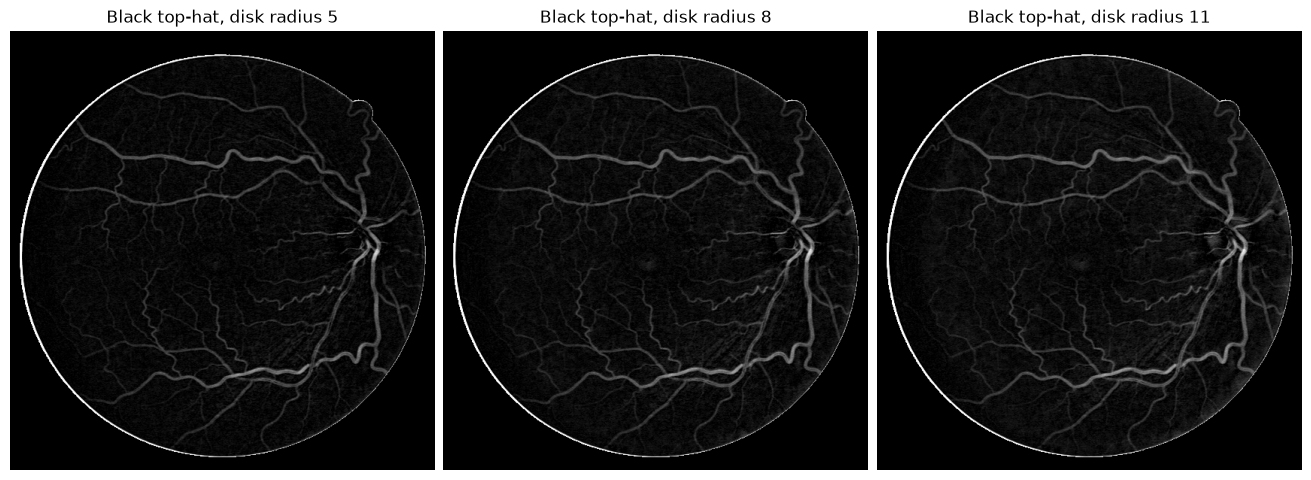

In [9]:
RADII = [5,8,11]

# One black top-hat per disk radius (closing of the image minus the image).
tophats = {r: morphology.black_tophat(green_fov, morphology.disk(r)) for r in RADII}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for ax, r in zip(axes, RADII):
    ax.imshow(np.where(fov, tophats[r], 0), cmap="gray")  # shown inside the FOV only
    ax.set_title(f"Black top-hat, disk radius {r}")
    ax.axis("off")
plt.show()

**Étape 5a : histogramme des niveaux de gris** de la réponse du top-hat (rayon 8), dans le FOV uniquement.
Pour chaque niveau de gris, le nombre de pixels qui l'ont : les vaisseaux sont dans la queue claire, à droite. Aide à choisir le seuil.

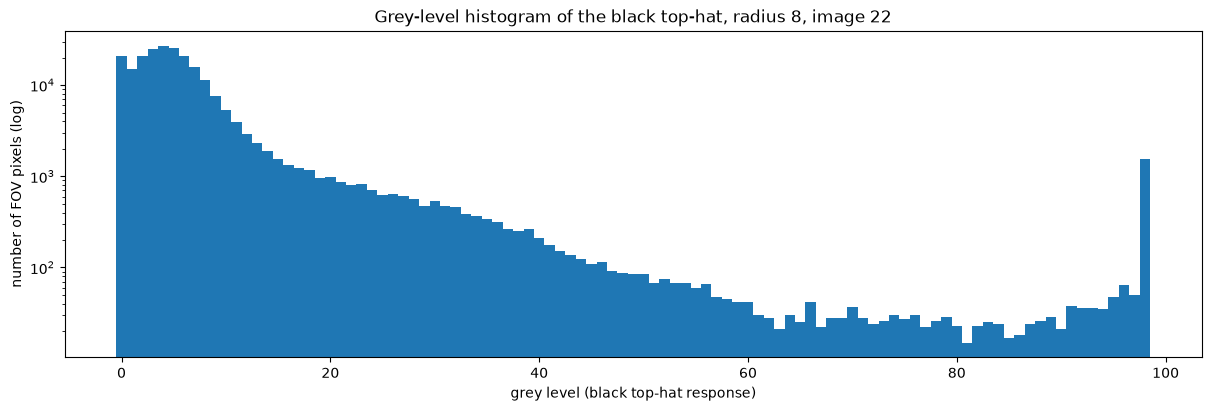

In [10]:
RADIUS = 8
tophat = tophats[RADIUS]

# Number of FOV pixels for each grey level of the top-hat (0, 1, 2, ...).
levels = np.arange(int(tophat[fov].max()) + 1)
counts = np.bincount(tophat[fov], minlength=levels.size)

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.bar(levels, counts, width=1.0)
ax.set_yscale("log")  # most pixels are near 0; log scale keeps the vessel tail visible
ax.set_xlabel("grey level (black top-hat response)")
ax.set_ylabel("number of FOV pixels (log)")
ax.set_title(f"Grey-level histogram of the black top-hat, radius {RADIUS}, image {IMG_ID}")
plt.show()

**Étape 5b : seuillage simple** avec une valeur choisie à la main : les pixels du top-hat plus clairs que `THRESHOLD` deviennent des vaisseaux.
Changer `THRESHOLD` puis relancer la cellule (et les suivantes). On obtient une première image binaire, sans opérateur morphologique.

threshold: 12
vessel pixels: 11.3% of the FOV (expert annotation: 13.1%)


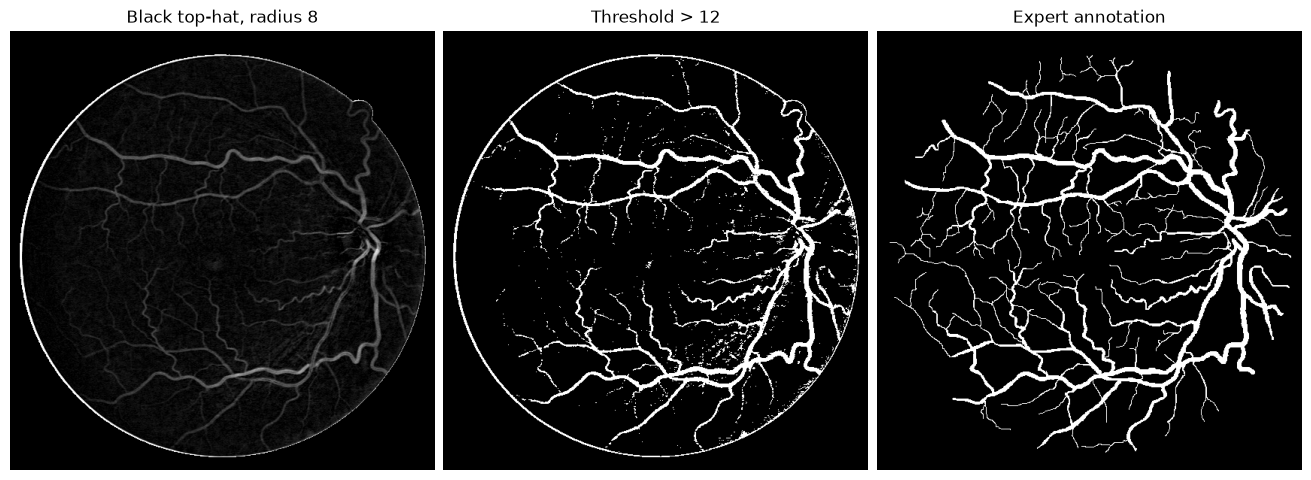

In [11]:
THRESHOLD = 12  # <- choose the grey level here (see the histogram above)

binary = (tophat > THRESHOLD) & fov

print(f"threshold: {THRESHOLD}")
print(f"vessel pixels: {binary[fov].mean():.1%} of the FOV (expert annotation: {vessels[fov].mean():.1%})")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for ax, (img, title) in zip(axes, [(np.where(fov, tophat, 0), f"Black top-hat, radius {RADIUS}"),
                                   (binary, f"Threshold > {THRESHOLD}"),
                                   (vessels, "Expert annotation")]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Étape 6 : nettoyage.** Ouverture par surface (`remove_small_objects`) : on supprime les composantes de 50 pixels ou moins, souvent du bruit.
Puis fermeture par un petit disque (rayon 1) pour reboucher les petites coupures dans les vaisseaux.

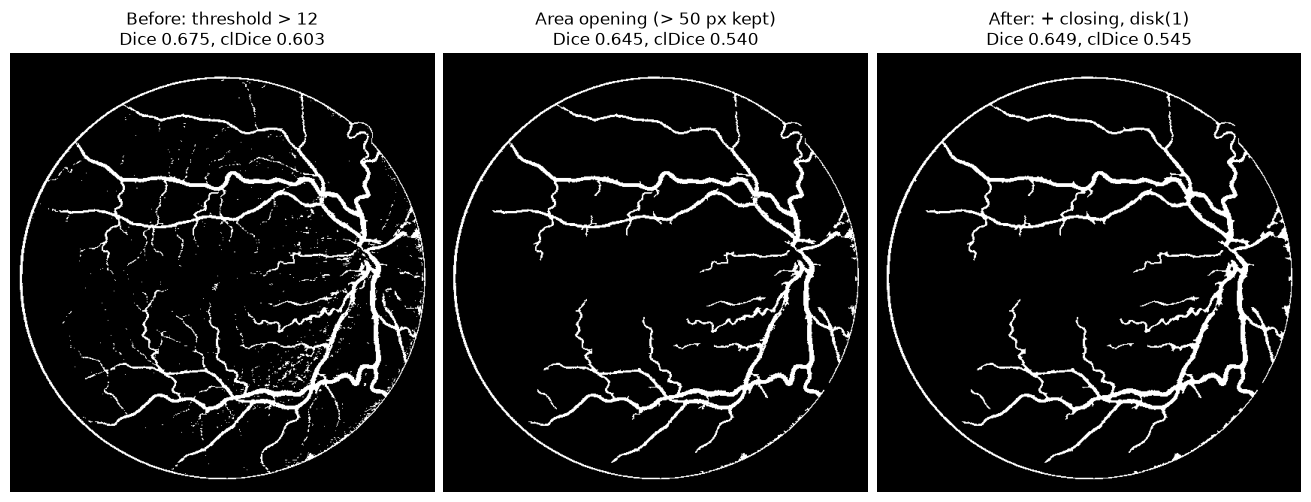

In [12]:
MIN_SIZE = 50  # components of MIN_SIZE pixels or fewer are removed

# Area opening: remove small connected components.
opened = morphology.remove_small_objects(binary, max_size=MIN_SIZE)
# Closing with a small disk: reconnect small gaps (kept inside the FOV).
closed = morphology.closing(opened, morphology.disk(1)) & fov

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for ax, (img, title) in zip(axes, [(binary, f"Before: threshold > {THRESHOLD}"),
                                   (opened, f"Area opening (> {MIN_SIZE} px kept)"),
                                   (closed, "After: + closing, disk(1)")]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{title}\nDice {dice_in_fov(img, vessels, fov):.3f}, "
                 f"clDice {cldice_in_fov(img, vessels, fov):.3f}")
    ax.axis("off")
plt.show()

**Étape 7 (optionnelle) : amincissement** (`thin`). Chaque vaisseau est réduit à une ligne d'un pixel d'épaisseur, son squelette.
C'est cette idée de ligne centrale qu'utilise le clDice pour mesurer la continuité des vaisseaux.

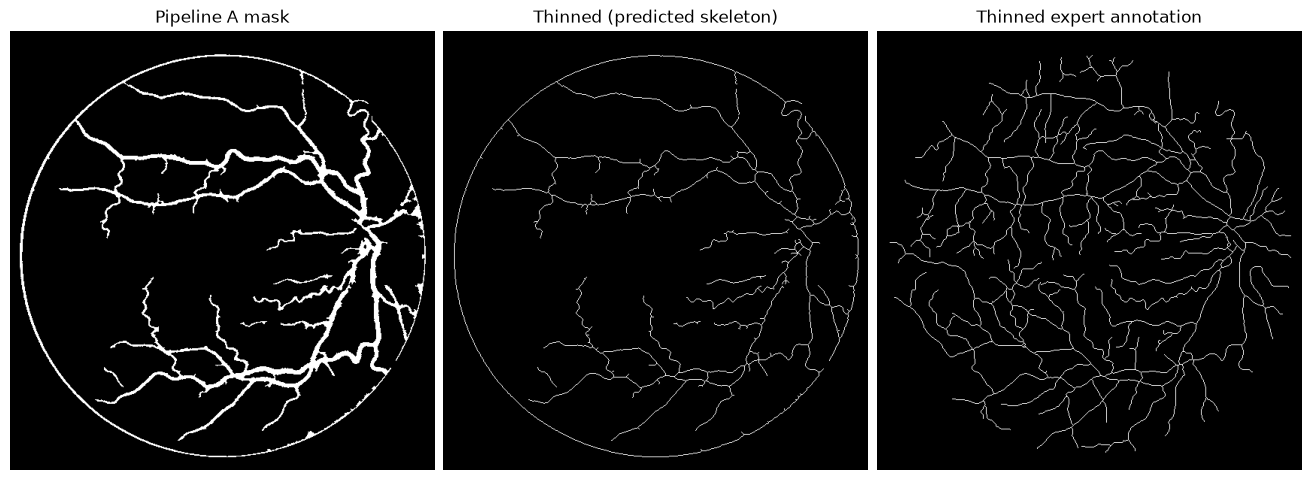

In [13]:
# Thinning: reduce each vessel to a one-pixel-wide centreline.
skeleton = morphology.thin(closed)
skeleton_truth = morphology.thin(vessels & fov)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for ax, (img, title) in zip(axes, [(closed, "Pipeline A mask"),
                                   (skeleton, "Thinned (predicted skeleton)"),
                                   (skeleton_truth, "Thinned expert annotation")]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Étape 8 : fonction `pipeline_a`** qui enchaîne les étapes 3 à 6 : masquage, top-hat conjugué, seuillage, ouverture par surface, fermeture.
Chaque étape a un interrupteur dans `config`, pour pouvoir en retirer une à la fois lors de l'étude d'ablation.

In [14]:
DEFAULT_CONFIG = {
    "fov_fill": True,       # step 3: fill outside the FOV with the mean green value
    "fill_outside": False,  # border fix 2: fill outside the FOV by cv2.inpaint (Telea, radius 5) instead of the mean
    "tophat": True,         # step 4: black top-hat (if False, threshold the inverted green channel)
    "radius": 8,            #         disk radius of the top-hat
    "border_erosion": True, # border fix 1: zero the top-hat outside the FOV eroded by a disk...
    "border_radius": 10,    #               ...of this radius (removes the bright ring at the FOV edge)
    "threshold": THRESHOLD, # step 5: a fixed grey level (from step 5b) or "otsu" (always applied: it makes the mask binary)
    "remove_small": True,   # step 6a: area opening
    "min_size": 50,         #          components of this size or smaller are removed
    "closing": True,        # step 6b: closing
    "closing_radius": 1,    #          disk radius of the closing
}


def pipeline_a(image, fov, config=None):
    """Pipeline A (morphology only). Returns (final binary mask, dict of intermediate images)."""
    cfg = {**DEFAULT_CONFIG, **(config or {})}
    steps = {}

    # Step 3: green channel, outside of the FOV filled by inpainting (fix 2) or with the FOV mean.
    g = image[..., 1].copy()
    if cfg["fill_outside"]:
        g = cv2.inpaint(g, (~fov).astype(np.uint8), 5, cv2.INPAINT_TELEA)
    elif cfg["fov_fill"]:
        g[~fov] = int(g[fov].mean())
    steps["green"] = g

    # Step 4: black top-hat, vessels become bright.
    if cfg["tophat"]:
        response = morphology.black_tophat(g, morphology.disk(cfg["radius"]))
    else:
        response = 255 - g  # without top-hat, invert so that vessels are bright too
    if cfg["border_erosion"]:
        # Fix 1: ignore a band along the FOV edge, where the bright ring is.
        fov_eroded = morphology.binary_erosion(fov, morphology.disk(cfg["border_radius"]))
        response = np.where(fov_eroded, response, 0)
    steps["response"] = response

    # Step 5: threshold, computed on FOV pixels for Otsu.
    t = threshold_otsu(response[fov]) if cfg["threshold"] == "otsu" else cfg["threshold"]
    mask = (response > t) & fov
    steps["threshold"] = t
    steps["binary"] = mask

    # Step 6: area opening, then closing.
    if cfg["remove_small"]:
        mask = morphology.remove_small_objects(mask, max_size=cfg["min_size"])
        steps["opened"] = mask
    if cfg["closing"]:
        mask = morphology.closing(mask, morphology.disk(cfg["closing_radius"])) & fov
        steps["closed"] = mask

    return mask, steps


# Check: with the border fixes off, the function reproduces the cells above.
pred, steps = pipeline_a(image, fov, {"border_erosion": False, "fill_outside": False})
print("same result as steps 3-6 (border fixes off):", np.array_equal(pred, closed))
print("intermediate images:", list(steps))

same result as steps 3-6 (border fixes off): True
intermediate images: ['green', 'response', 'threshold', 'binary', 'opened', 'closed']


**Étape 9 : résultat sur une image.** Image originale, vérité terrain et prédiction de `pipeline_a` côte à côte,
avec le Dice (recouvrement) et le clDice (continuité, via les squelettes) calculés dans le FOV.

/tmp/ipykernel_666756/1123920996.py:36: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  fov_eroded = morphology.binary_erosion(fov, morphology.disk(cfg["border_radius"]))


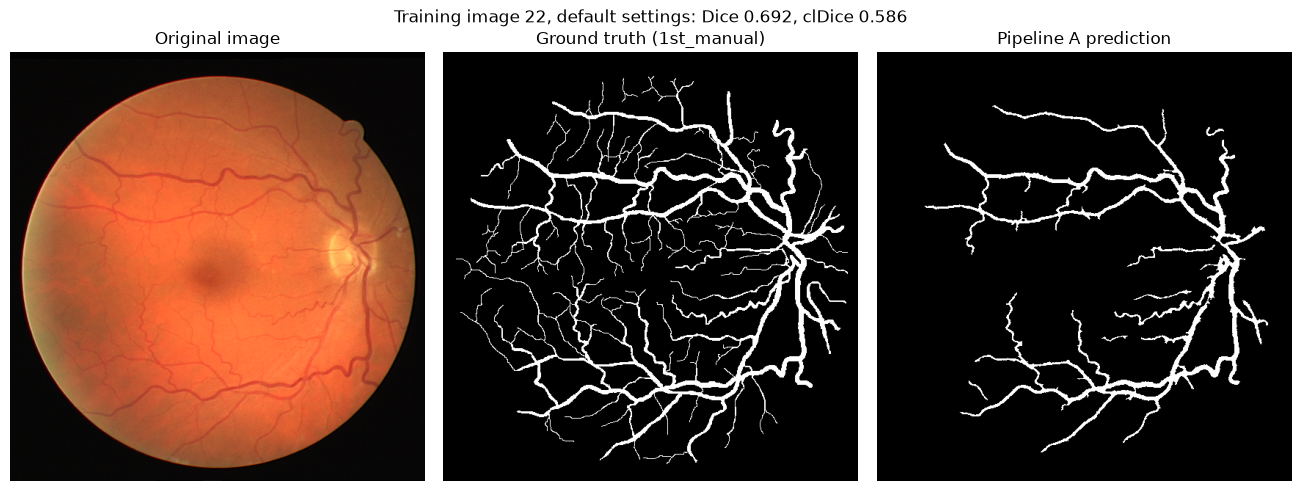

In [15]:
pred, steps = pipeline_a(image, fov, DEFAULT_CONFIG)
dice = dice_in_fov(pred, vessels, fov)
cldice = cldice_in_fov(pred, vessels, fov)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for ax, (img, cmap, title) in zip(axes, [(image, None, "Original image"),
                                         (vessels, "gray", "Ground truth (1st_manual)"),
                                         (pred, "gray", "Pipeline A prediction")]):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle(f"Training image {IMG_ID}, default settings: Dice {dice:.3f}, clDice {cldice:.3f}")
plt.show()

**Étape 10 : réglage sur les 20 images d'entraînement uniquement (21 à 40).** Petite grille de rayons du disque (top-hat conjugué)
et de seuils (Otsu ou valeur fixe) ; chaque réglage est noté par le Dice et le clDice moyens. Les images de test ne sont jamais utilisées ici.

In [16]:
# Training images only (21-40). The test images (01-20) are never loaded in this section.
TRAIN_IDS = list(range(21, 41))
train_set = [(read_rgb(DRIVE / "training" / "images" / f"{i}_training.tif"),
              read_binary(DRIVE / "training" / "mask" / f"{i}_training_mask.gif"),
              read_binary(DRIVE / "training" / "1st_manual" / f"{i}_manual1.gif"))
             for i in TRAIN_IDS]

GRID_RADII = [4, 6, 8, 10, 12]
GRID_THRESHOLDS = ["otsu", 8, 10, 12, 15]  # fixed values are top-hat grey levels

results = []
for r in GRID_RADII:
    for t in GRID_THRESHOLDS:
        config = {"radius": r, "threshold": t}  # everything else as in DEFAULT_CONFIG
        dices, cldices = [], []
        for img_i, fov_i, vessels_i in train_set:
            pred_i, _ = pipeline_a(img_i, fov_i, config)
            dices.append(dice_in_fov(pred_i, vessels_i, fov_i))
            cldices.append(cldice_in_fov(pred_i, vessels_i, fov_i))
        results.append((r, t, np.mean(dices), np.mean(cldices)))

# Table sorted by mean clDice, best first.
results.sort(key=lambda row: row[3], reverse=True)
print(f"{'radius':>6}  {'threshold':>9}  {'Dice':>6}  {'clDice':>6}")
for r, t, d, c in results:
    print(f"{r:>6}  {str(t):>9}  {d:6.3f}  {c:6.3f}")

/tmp/ipykernel_666756/1123920996.py:36: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  fov_eroded = morphology.binary_erosion(fov, morphology.disk(cfg["border_radius"]))


radius  threshold    Dice  clDice
     6          8   0.718   0.694
     8          8   0.688   0.683
    10         10   0.686   0.661
     8         10   0.699   0.661
    12         10   0.671   0.655
    10          8   0.647   0.653
     4          8   0.691   0.653
     6         10   0.696   0.646
    12         12   0.673   0.631
    12          8   0.612   0.628
    10         12   0.674   0.625
     8         12   0.670   0.612
     6         12   0.647   0.584
     4         10   0.619   0.571
     4       otsu   0.615   0.568
    12         15   0.621   0.554
     6       otsu   0.619   0.554
     8       otsu   0.621   0.553
    12       otsu   0.617   0.552
    10       otsu   0.617   0.551
    10         15   0.612   0.543
     8         15   0.592   0.522
     4         12   0.535   0.485
     6         15   0.550   0.483
     4         15   0.415   0.373


### Correction de l'anneau clair au bord du FOV
**Correctif 1 : érosion du masque du FOV** (`binary_erosion`, disque de rayon 10). Le top-hat est mis à zéro hors du FOV érodé :
la bande de 10 pixels le long du bord, où se trouve l'anneau, est ignorée.

In [17]:
# Fix 1: erode the FOV mask with a disk of radius 10, then zero the top-hat outside it.
fov_eroded = morphology.binary_erosion(fov, morphology.disk(10))
tophat_fix1 = np.where(fov_eroded, tophat, 0)

print(f"FOV: {fov.sum()} px, eroded FOV: {fov_eroded.sum()} px "
      f"({1 - fov_eroded.sum() / fov.sum():.1%} of the FOV is ignored)")
print(f"vessel pixels of the annotation in the ignored band: {(vessels & fov & ~fov_eroded).sum()}")

FOV: 227686 px, eroded FOV: 211145 px (7.3% of the FOV is ignored)
vessel pixels of the annotation in the ignored band: 870


/tmp/ipykernel_666756/941212797.py:2: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  fov_eroded = morphology.binary_erosion(fov, morphology.disk(10))


**Correctif 2 : remplir l'extérieur du FOV avant le top-hat**, avec `cv2.inpaint` (méthode de Telea, rayon 5) sur le canal vert.
Les valeurs du bord sont prolongées vers l'extérieur : il n'y a plus de marche nette, et le top-hat conjugué est recalculé sur cette image.

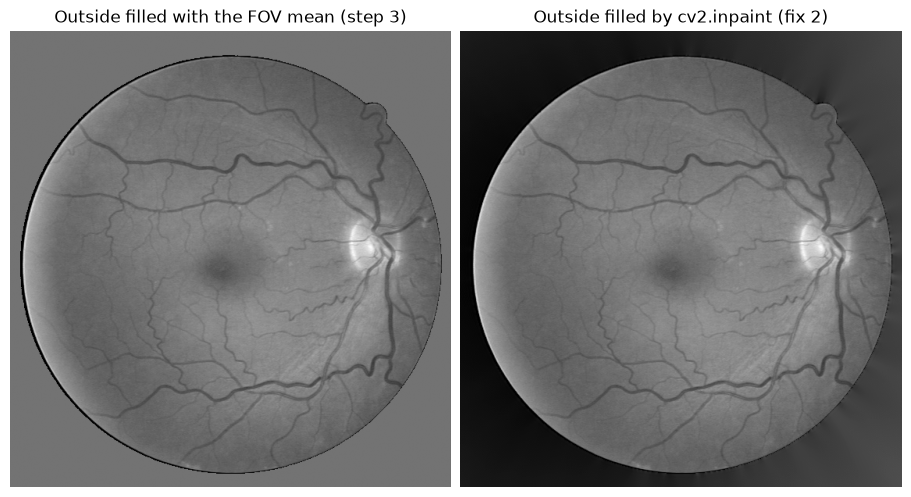

In [18]:
# Fix 2: inpaint the green channel outside the FOV (inpaint mask = pixels to fill = outside the FOV).
outside = (~fov).astype(np.uint8)
green_inpainted = cv2.inpaint(np.ascontiguousarray(green), outside, 5, cv2.INPAINT_TELEA)
tophat_fix2 = morphology.black_tophat(green_inpainted, morphology.disk(RADIUS))

# Both fixes: top-hat of the inpainted image, then zeroed outside the eroded FOV.
tophat_both = np.where(fov_eroded, tophat_fix2, 0)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.8), layout="constrained")
for ax, (img, title) in zip(axes, [(green_fov, "Outside filled with the FOV mean (step 3)"),
                                   (green_inpainted, "Outside filled by cv2.inpaint (fix 2)")]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

**Comparaison des quatre versions** sur l'image `IMG_ID` : sans correctif, correctif 1 seul, correctif 2 seul, les deux.
Même seuil `THRESHOLD` pour toutes. Dice et clDice après le seuillage, puis après le nettoyage (ouverture par surface + fermeture).

threshold > 12, image 22
version               after threshold         after clean-up
no fix           Dice 0.675 clDice 0.603   Dice 0.649 clDice 0.545
fix 1: erosion   Dice 0.721 clDice 0.653   Dice 0.692 clDice 0.586
fix 2: inpaint   Dice 0.708 clDice 0.621   Dice 0.688 clDice 0.575
fix 1 + fix 2    Dice 0.721 clDice 0.653   Dice 0.692 clDice 0.586


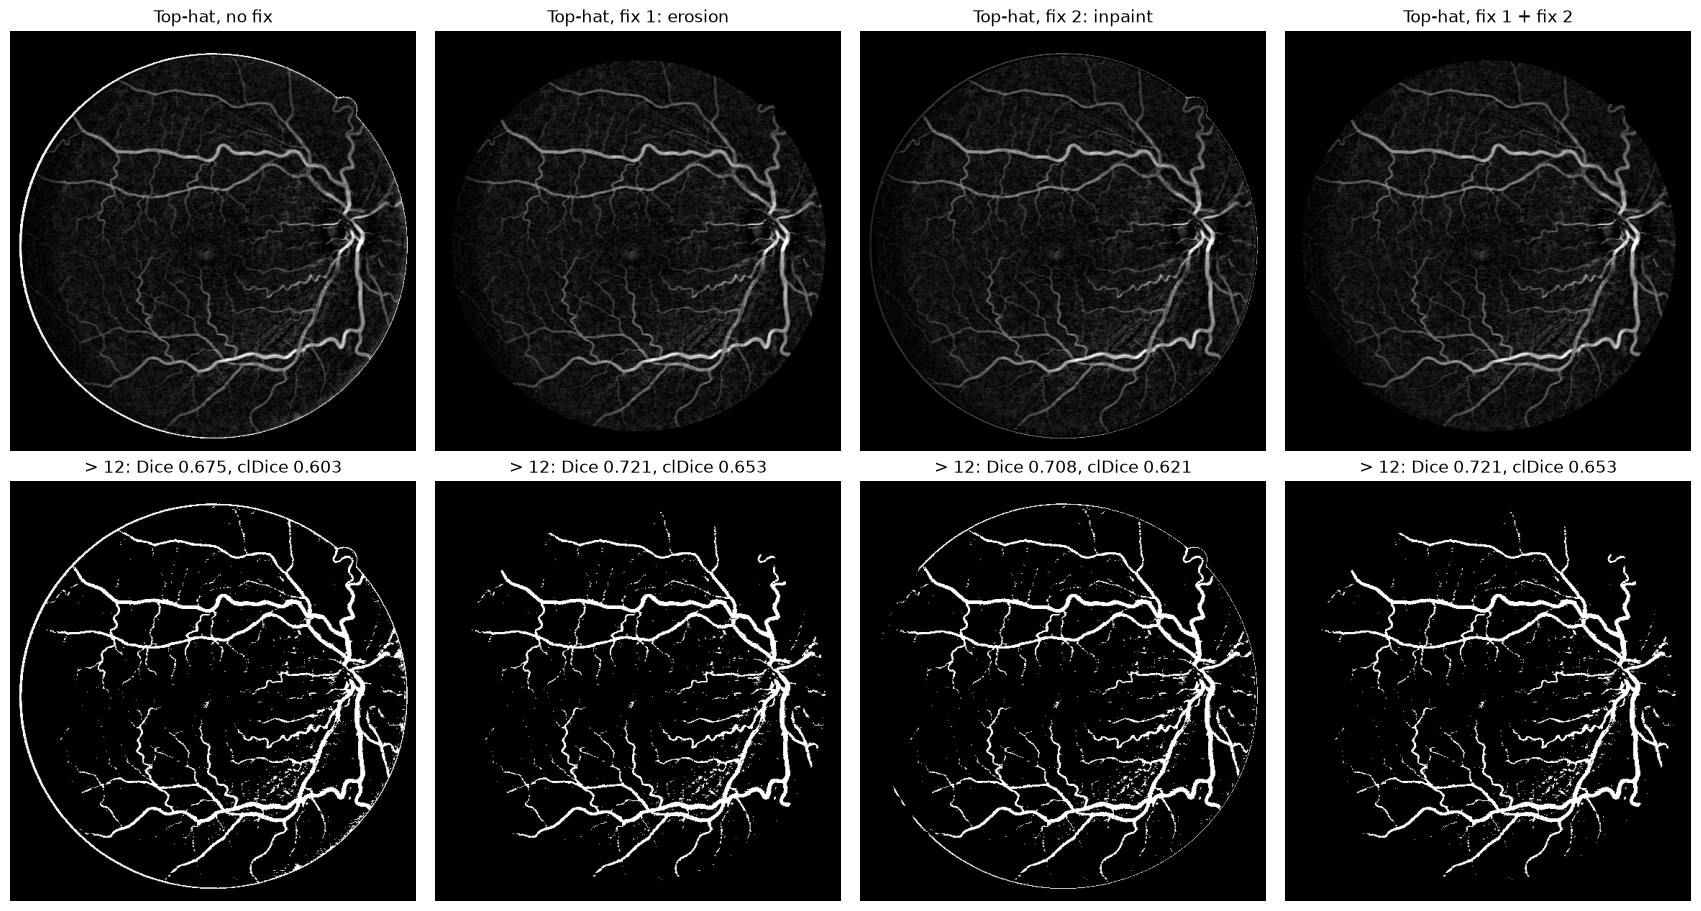

In [19]:
versions = {
    "no fix": tophat,
    "fix 1: erosion": tophat_fix1,
    "fix 2: inpaint": tophat_fix2,
    "fix 1 + fix 2": tophat_both,
}

fig, axes = plt.subplots(2, 4, figsize=(17, 9), layout="constrained")
print(f"threshold > {THRESHOLD}, image {IMG_ID}")
print(f"{'version':<16} {'after threshold':>20}   {'after clean-up':>20}")
for col, (name, th) in enumerate(versions.items()):
    # Same threshold, then the same clean-up as step 6.
    bin_v = (th > THRESHOLD) & fov
    clean_v = morphology.closing(morphology.remove_small_objects(bin_v, max_size=MIN_SIZE), morphology.disk(1)) & fov
    d1, c1 = dice_in_fov(bin_v, vessels, fov), cldice_in_fov(bin_v, vessels, fov)
    d2, c2 = dice_in_fov(clean_v, vessels, fov), cldice_in_fov(clean_v, vessels, fov)
    print(f"{name:<16} Dice {d1:.3f} clDice {c1:.3f}   Dice {d2:.3f} clDice {c2:.3f}")

    axes[0, col].imshow(np.where(fov, th, 0), cmap="gray", vmin=0, vmax=60)  # same scale for all four
    axes[0, col].set_title(f"Top-hat, {name}")
    axes[1, col].imshow(bin_v, cmap="gray")
    axes[1, col].set_title(f"> {THRESHOLD}: Dice {d1:.3f}, clDice {c1:.3f}")
for ax in axes.flat:
    ax.axis("off")
plt.show()

**Choix par défaut dans `pipeline_a`.** Les deux correctifs sont devenus des options de la configuration (étape 8) : `border_erosion` et `fill_outside`.
Les quatre combinaisons sont comparées sur les 20 images d'entraînement (jamais le test) ; la valeur par défaut est la meilleure.

In [20]:
print(f"{'border_erosion':>14} {'fill_outside':>12}  {'Dice':>6} {'clDice':>6}")
for erosion in [False, True]:
    for fill in [False, True]:
        config = {"border_erosion": erosion, "fill_outside": fill}
        scores = [(dice_in_fov(p, v, f), cldice_in_fov(p, v, f))
                  for img_i, f, v in train_set
                  for p in [pipeline_a(img_i, f, config)[0]]]
        print(f"{str(erosion):>14} {str(fill):>12}  {np.mean([s[0] for s in scores]):6.3f} {np.mean([s[1] for s in scores]):6.3f}")

print("\ndefault:", {k: DEFAULT_CONFIG[k] for k in ["border_erosion", "fill_outside"]})

border_erosion fill_outside    Dice clDice
         False        False   0.638  0.574
         False         True   0.670  0.606


/tmp/ipykernel_666756/1123920996.py:36: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  fov_eroded = morphology.binary_erosion(fov, morphology.disk(cfg["border_radius"]))


          True        False   0.670  0.612
          True         True   0.670  0.612

default: {'border_erosion': True, 'fill_outside': False}
